In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))

# OVReader figures

Reproduces the OVReader data charts (paper `fig:ovreader` main + `fig:ov-faithfulness` /
`fig:ov-causality` appendix) and saves PDFs (+PNG) to `notebooks/Figures/ovreader/`.

Data is read straight from `results/evaluation/ov-reader/<model>/<layer>/<mode>/<leaf>/summary.json`
via the shared IO helper `scripts/evaluation/ov_reader_io.py` (`grid_df` -> per-(layer, pivot, datatype)
`hard_yes`). The `goalscope` layer dir is the head-output reference (dashed line), **not** a probe layer.
Main pivot position is `eq` (the assignment pivot); the `first_impl` pivot is excluded throughout.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import figstyle
from scripts.evaluation import ov_reader_io as ovio

figstyle.set_style()

MODEL   = "Qwen/Qwen2.5-Coder-32B-Instruct"
MSLUG   = MODEL.split("/")[-1]
PIVOT   = "eq"                      # assignment pivot = main OVReader position
RR      = env_utils.determine_results_dir()
SKY     = ovio.SKYLINE_IDX          # "goalscope"

def load_metric(mode, pivot=PIVOT):
    """Return (layers, dtypes, {dt: hard_yes-over-layers}, {dt: goalscope-ref}) at `pivot`."""
    df = ovio.grid_df(RR, mode=mode, model=MODEL)
    df = df[df["pivot"] == pivot]
    piv = df.pivot_table(index="layer_idx", columns="datatype", values="hard_yes")
    dtypes = sorted(piv.columns.tolist())
    ref = {dt: (piv.loc[SKY, dt] if SKY in piv.index else np.nan) for dt in dtypes}
    piv = piv.drop(index=SKY, errors="ignore")
    layers = sorted(int(x) for x in piv.index)
    curves = {dt: piv.loc[layers, dt].to_numpy(dtype=float) for dt in dtypes}
    return layers, dtypes, curves, ref

FAI = load_metric("faithfulness")
CAU = load_metric("causality")
DTYPES = FAI[1]
DT_COLOR = {dt: figstyle.OKABE_ITO[i] for i, dt in enumerate(DTYPES)}
print("layers:", FAI[0])
print("datatypes:", DTYPES)
print("pre-impl pivots available in figstyle:", figstyle.PIVOTS)

layers: [0, 6, 12, 18, 24, 30, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 60, 63]
datatypes: ['int', 'list[int]', 'list[str]', 'str']
pre-impl pivots available in figstyle: ['prev_end', 'indent', 'var', 'eq']


In [3]:
def plot_per_datatype(metric_data, title, save_name):
    layers, dtypes, curves, ref = metric_data
    x = np.array(layers)
    mean = np.nanmean(np.stack([curves[dt] for dt in dtypes]), axis=0)
    ref_mean = float(np.nanmean([ref[dt] for dt in dtypes]))

    fig, ax = plt.subplots(figsize=(5.4, 3.4))
    for dt in dtypes:
        ax.plot(x, curves[dt], marker="o", ms=3.5, lw=1.2, alpha=0.85,
                color=DT_COLOR[dt], label=dt)
    ax.plot(x, mean, marker="s", ms=4.5, lw=2.2, color="black", label="mean", zorder=5)
    ax.axhline(ref_mean, ls="--", lw=1.4, color="0.35",
               label=f"GoalScope head-output ({ref_mean:.2f})")

    ax.set_xlabel("source layer")
    ax.set_ylabel("hard-yes rate")
    ax.set_title(title)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xticks(x[::2])
    ax.legend(frameon=False, ncol=2, fontsize=7.5, loc="lower right")
    fig.tight_layout()
    p = figstyle.save_fig(fig, "ovreader", save_name)
    print("saved", p, "| peak mean =", f"{np.nanmax(mean):.3f}",
          "@ layer", int(x[np.nanargmax(mean)]))
    return fig

## Fig 1 - `ov_faithfulness` (appendix `fig:ov-faithfulness`)

OVReader **faithfulness** `hard_yes` vs. source layer at the `eq` pivot: one curve per datatype,
a bold black mean curve, and the `goalscope` head-output value as a dashed horizontal reference.

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ovreader/ov_faithfulness.pdf | peak mean = 0.948 @ layer 48


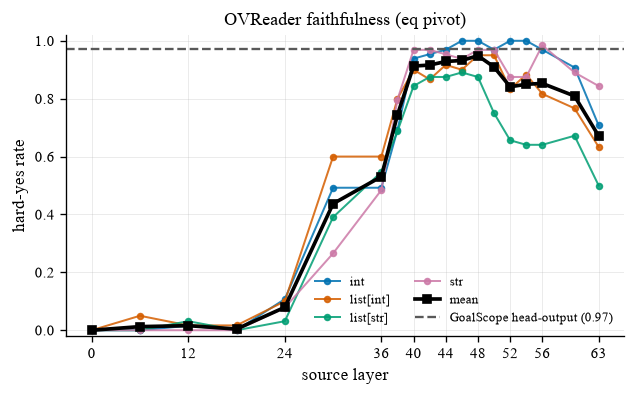

In [4]:
_ = plot_per_datatype(FAI, "OVReader faithfulness (eq pivot)", "ov_faithfulness")

## Fig 2 - `ov_causality` (appendix `fig:ov-causality`)

Same as Fig 1 for the **causality** mode.

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ovreader/ov_causality.pdf | peak mean = 0.908 @ layer 44


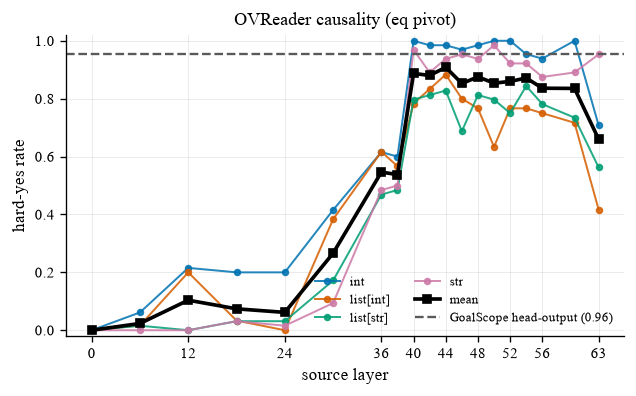

In [5]:
_ = plot_per_datatype(CAU, "OVReader causality (eq pivot)", "ov_causality")

## Fig 3 - `ov_reader_combined` (main-body `fig:ovreader`)

Compact main-body version: faithfulness and causality vs. layer at the `eq` pivot, each the mean over
datatypes with a +/-1 SD band. Per the figstyle metric convention faithfulness is **solid** and causality
is **dashed** (the line analogue of the solid/hatched fill convention); both use the `eq` pivot colour.
The GoalScope head-output means are thin dotted reference lines.

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ovreader/ov_reader_combined.pdf
faithfulness peak mean = 0.948 @ layer 48 | goalscope ref = 0.972
causality    peak mean = 0.908 @ layer 44 | goalscope ref = 0.955


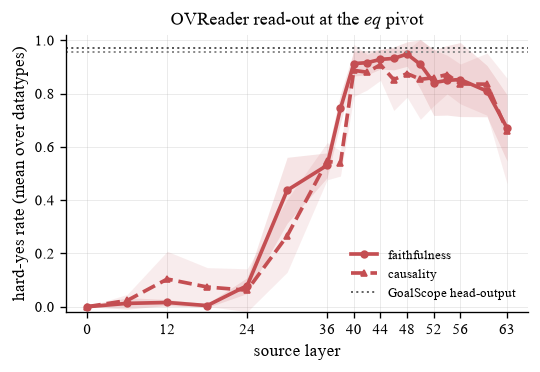

In [6]:
def _mean_sd(md):
    layers, dtypes, curves, ref = md
    stk = np.stack([curves[dt] for dt in dtypes])
    return (np.array(layers), np.nanmean(stk, axis=0), np.nanstd(stk, axis=0),
            float(np.nanmean([ref[dt] for dt in dtypes])))

xf, mf, sf, rf = _mean_sd(FAI)
xc, mc, sc, rc = _mean_sd(CAU)
col = figstyle.PIVOT_COLOR[PIVOT]

fig, ax = plt.subplots(figsize=(4.6, 3.2))
ax.fill_between(xf, mf - sf, mf + sf, color=col, alpha=0.15, linewidth=0)
ax.plot(xf, mf, marker="o", ms=4, lw=2.2, color=col, ls="-", label="faithfulness")
ax.fill_between(xc, mc - sc, mc + sc, color=col, alpha=0.10, linewidth=0)
ax.plot(xc, mc, marker="^", ms=4, lw=2.2, color=col, ls="--", label="causality")
ax.axhline(rf, ls=":", lw=1.2, color="0.35")
ax.axhline(rc, ls=":", lw=1.2, color="0.55")

ax.set_xlabel("source layer")
ax.set_ylabel("hard-yes rate (mean over datatypes)")
ax.set_title(r"OVReader read-out at the $eq$ pivot")
ax.set_ylim(-0.02, 1.02)
ax.set_xticks(xf[::2])

from matplotlib.lines import Line2D
handles = [
    Line2D([], [], color=col, ls="-", marker="o", ms=4, lw=2.2, label="faithfulness"),
    Line2D([], [], color=col, ls="--", marker="^", ms=4, lw=2.2, label="causality"),
    Line2D([], [], color="0.4", ls=":", lw=1.2, label="GoalScope head-output"),
]
ax.legend(handles=handles, frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
p = figstyle.save_fig(fig, "ovreader", "ov_reader_combined")
print("saved", p)
print(f"faithfulness peak mean = {np.nanmax(mf):.3f} @ layer {int(xf[np.nanargmax(mf)])} "
      f"| goalscope ref = {rf:.3f}")
print(f"causality    peak mean = {np.nanmax(mc):.3f} @ layer {int(xc[np.nanargmax(mc)])} "
      f"| goalscope ref = {rc:.3f}")